# Toy demo: how we get from EEG to microstates

Our pipeline: **EEG (19 channels) → GFP → GFP peaks → modified k-means (4 maps) → label every sample → features**.

Here every step is run on **made-up signals built from sine waves**, where we know the right
answer, so we can see what each step does. At the end, the same steps run on 2 seconds of real EEG.

| Part | Signal | What it shows |
|---|---|---|
| 1 | one sine wave on one channel | GFP needs many channels: with one channel it is 0 |
| 2 | one 10 Hz sine wave on 19 channels with a fixed scalp pattern | what GFP is; why it has 2 peaks per cycle; why we use the peaks |
| 3 | 50 + 100 + 200 + 300 Hz mixed | GFP is plotted against **time**, the Fourier transform against **frequency** |
| 4 | 4 known scalp patterns switching every 40–120 ms | the whole method finds the 4 hidden patterns and the sequence again |
| 5 | 2 seconds of real EEG (h01) | the same picture on our data |

Library used in the project: **pycrostates 0.6.1** (built on **MNE**).
`pycrostates.preprocessing.extract_gfp_peaks` finds the peaks,
`pycrostates.cluster.ModKMeans` does the clustering and the labelling. Docs: https://pycrostates.readthedocs.io

In [1]:
# Settings and imports (seed 42, as in the whole project)
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import mne
import numpy as np
from scipy.signal import find_peaks

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "scripts"))
import microstate_model as mm          # our own module (GFP formula, settings)
import eeg_preprocessing as pre        # our own module (loading and cleaning the EEG)
from pycrostates.cluster import ModKMeans
from pycrostates.io import ChData
from pycrostates.preprocessing import extract_gfp_peaks

SEED = 42
rng = np.random.default_rng(SEED)
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# The 19 electrodes of our data, on the standard 10-20 head (the same as the project)
CH = ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "T7", "C3", "Cz", "C4", "T8",
      "P7", "P3", "Pz", "P4", "P8", "O1", "O2"]
def head_info(sfreq):
    info = mne.create_info(CH, sfreq, "eeg")
    info.set_montage("standard_1020")
    return info

def topo(ax, values, info, title=""):
    mne.viz.plot_topomap(values, info, axes=ax, show=False, contours=0, cmap="RdBu_r", sensors=True)
    ax.set_title(title, fontsize=9)

def gfp(data):
    # GFP at every sample = standard deviation across the channels (data: channels x samples)
    return data.std(axis=0)
print("ready")

ready


## Part 1 - one sine wave, one channel

A 10 Hz sine wave, sampled at 250 Hz (our sampling rate) for 1 second.

**GFP (global field power)** at one moment = how different the electrodes are from each other at
that moment = the standard deviation across the electrodes:

$$\mathrm{GFP}(t)=\sqrt{\tfrac{1}{N}\sum_{i=1}^{N}\big(V_i(t)-\bar V(t)\big)^2}$$

With only **one** channel there is nothing to compare, so GFP is 0 at every moment.
GFP is a measure **across the scalp**, so it needs many channels.

GFP with one channel, largest value: 0.0


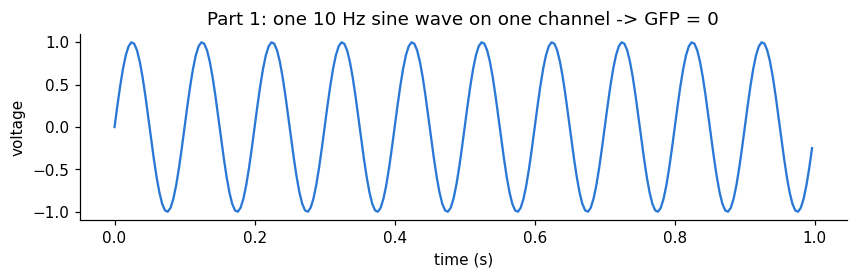

In [2]:
fs, f = 250, 10                                # sampling rate (Hz), sine frequency (Hz)
t = np.arange(0, 1, 1 / fs)                    # 1 second = 250 samples
one_channel = np.sin(2 * np.pi * f * t)[None, :]   # shape (1 channel, 250 samples)
print("GFP with one channel, largest value:", gfp(one_channel).max())

fig, ax = plt.subplots(figsize=(9, 2.2))
ax.plot(t, one_channel[0], color="#2a78d6")
ax.set(xlabel="time (s)", ylabel="voltage", title="Part 1: one 10 Hz sine wave on one channel -> GFP = 0")
plt.show()

## Part 2 - one 10 Hz sine wave on 19 channels with a fixed scalp pattern

Now the same 10 Hz wave appears on all 19 electrodes, but each electrode gets a different
strength (a fixed **scalp pattern**, or map: here front electrodes positive, back electrodes
negative). This is what a brain source looks like on the scalp: one pattern whose strength
goes up and down.

Steps in the next cell:
1. build the 19-channel signal: pattern × sine wave (+ a little noise);
2. **average reference**: subtract the mean of the 19 channels at every sample (as in our pipeline);
3. GFP at every sample;
4. **GFP peaks** = samples where GFP is higher than both neighbours (a *local maximum*),
   found with `scipy.signal.find_peaks(gfp, distance=2)`. This is exactly what
   `extract_gfp_peaks(raw, min_peak_distance=2)` does inside pycrostates;
   we call it on the same signal as a check.

peaks found by find_peaks: 20,  by pycrostates: 20
10 Hz wave -> 20 GFP peaks in 1 s  (2 per cycle: one at the top, one at the bottom)


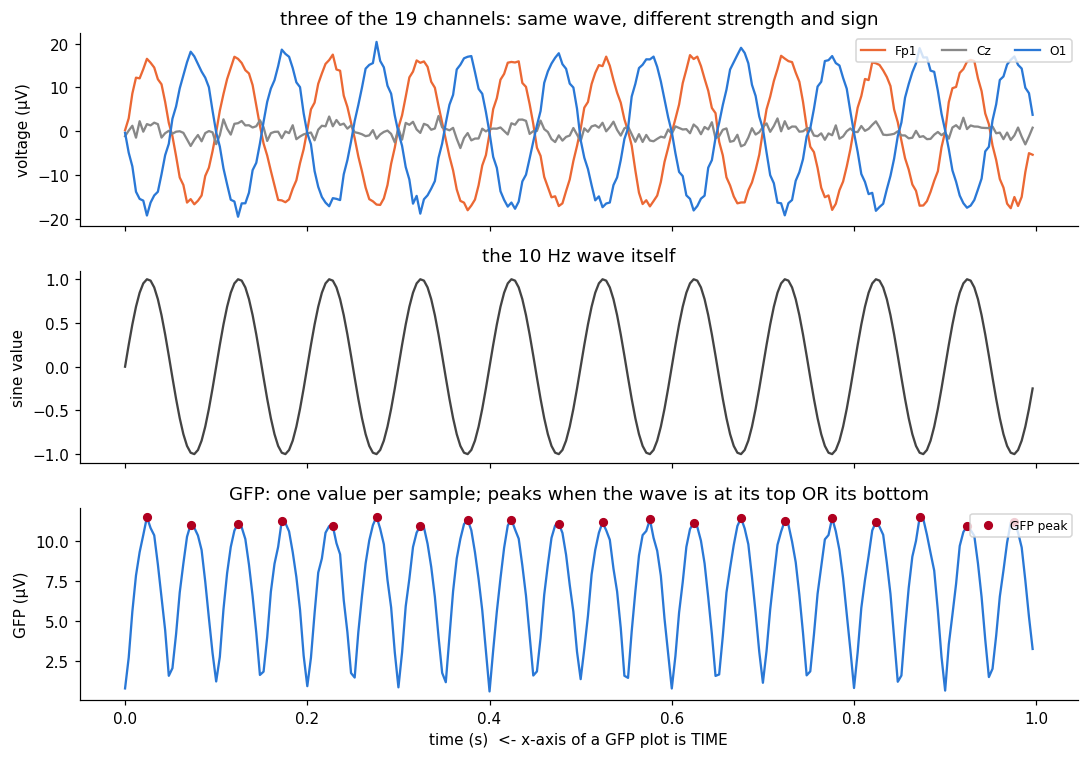

In [3]:
info = head_info(fs)
pos = np.array([info.get_montage().get_positions()["ch_pos"][c] for c in CH])
x, y = pos[:, 0] / np.abs(pos[:, 0]).max(), pos[:, 1] / np.abs(pos[:, 1]).max()   # left-right, back-front
pattern = y - y.mean()                       # front positive, back negative (like map C)

wave = np.sin(2 * np.pi * f * t)
data = pattern[:, None] * wave[None, :] * 20e-6            # 20 microvolt scale, channels x samples
data += rng.normal(0, 1e-6, data.shape)                     # small noise
data -= data.mean(axis=0, keepdims=True)                    # average reference

g = gfp(data)
peaks, _ = find_peaks(g, distance=2)                        # local maxima of GFP
raw = mne.io.RawArray(data, info)
peaks_lib = extract_gfp_peaks(raw, min_peak_distance=2)     # the library function we use
print(f"peaks found by find_peaks: {len(peaks)},  by pycrostates: {peaks_lib.get_data().shape[1]}")
print(f"{f} Hz wave -> {len(peaks)} GFP peaks in 1 s  (2 per cycle: one at the top, one at the bottom)")

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ch, c in [("Fp1", "#eb6834"), ("Cz", "#888888"), ("O1", "#2a78d6")]:
    axes[0].plot(t, data[CH.index(ch)] * 1e6, color=c, label=ch)
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[0].set(ylabel="voltage (µV)", title="three of the 19 channels: same wave, different strength and sign")
axes[1].plot(t, wave, color="#444444")
axes[1].set(ylabel="sine value", title="the 10 Hz wave itself")
axes[2].plot(t, g * 1e6, color="#2a78d6")
axes[2].plot(t[peaks], g[peaks] * 1e6, "o", color="#b00020", ms=5, label="GFP peak")
axes[2].legend(loc="upper right", fontsize=8)
axes[2].set(xlabel="time (s)  <- x-axis of a GFP plot is TIME", ylabel="GFP (µV)",
            title="GFP: one value per sample; peaks when the wave is at its top OR its bottom")
plt.tight_layout(); plt.show()

**What the plot tells:**
* x-axis = **time** (seconds), y-axis = **GFP in microvolts**. GFP is not a frequency plot.
* GFP is high when the wave is at its top **and** at its bottom (the electrodes are most different
  from each other then), and about 0 when the wave crosses zero. So a 10 Hz wave gives
  **20 GFP peaks per second**.
* At the top and the bottom the map is the **same pattern with the colours flipped**. That is why
  modified k-means **ignores polarity**: both belong to the same microstate.

Below: the map at two peaks next to each other, and at a GFP minimum. Then **why we use the peaks**:
for every sample we measure how close the map at that moment is to the true pattern
(|correlation|). Where GFP is high the map is clean (|corr| close to 1); where GFP is low the map
is mostly noise.

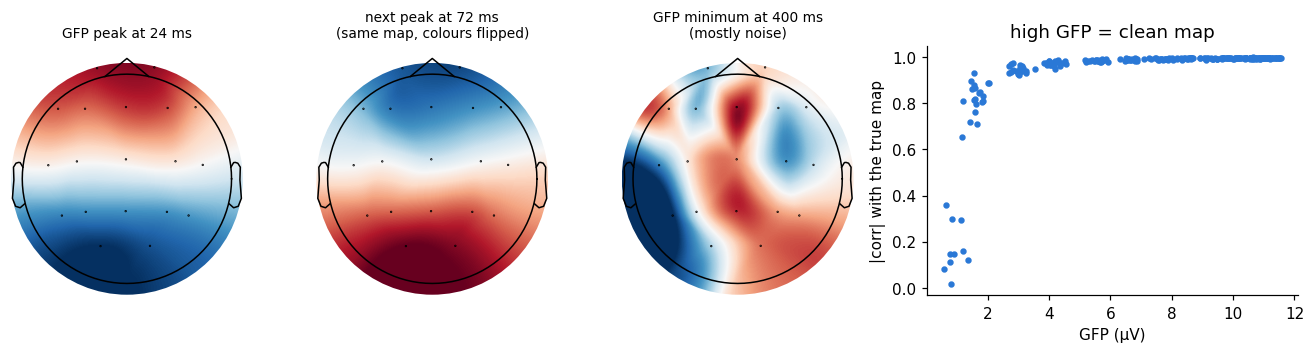

In [4]:
low = int(np.argmin(g[: fs // 2]))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
topo(axes[0], data[:, peaks[0]], info, f"GFP peak at {t[peaks[0]]*1000:.0f} ms")
topo(axes[1], data[:, peaks[1]], info, f"next peak at {t[peaks[1]]*1000:.0f} ms\n(same map, colours flipped)")
topo(axes[2], data[:, low], info, f"GFP minimum at {t[low]*1000:.0f} ms\n(mostly noise)")
corr = np.abs([np.corrcoef(data[:, i], pattern)[0, 1] for i in range(len(t))])
axes[3].scatter(g * 1e6, corr, s=10, color="#2a78d6")
axes[3].set(xlabel="GFP (µV)", ylabel="|corr| with the true map", title="high GFP = clean map")
plt.tight_layout(); plt.show()

## Part 3 - the mixture of 50, 100, 200 and 300 Hz

To hold a 300 Hz wave we must sample faster than 2 × 300 = 600 Hz (Nyquist), so this part uses
**1000 Hz** (our EEG is 250 Hz). The four waves are added and put on the same scalp pattern.

* **Fourier transform** (x-axis = frequency): shows the four frequencies 50, 100, 200, 300 Hz.
* **GFP** (x-axis = time): shows *when* the scalp field is strong. The peaks are not at
  "100 Hz"; they are moments in time.

Two different tools for two different questions: *which rhythms are there?* (Fourier) and
*when is the scalp pattern strongest?* (GFP).

Note: our EEG is filtered 2–20 Hz before microstates, so these fast waves would be removed.
They are only a test signal here.

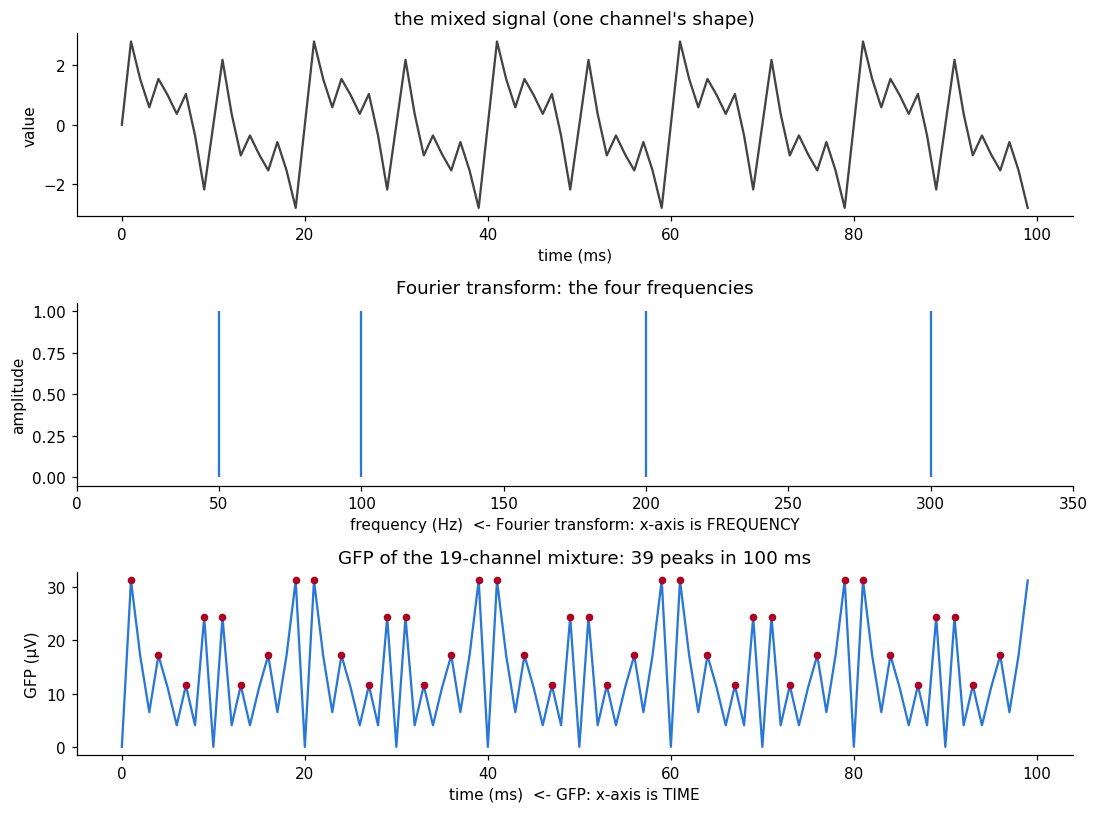

In [5]:
fs3 = 1000
t3 = np.arange(0, 0.1, 1 / fs3)                       # 100 ms is enough to see the peaks
mix = sum(np.sin(2 * np.pi * fr * t3) for fr in (50, 100, 200, 300))
data3 = pattern[:, None] * mix[None, :] * 20e-6
data3 -= data3.mean(axis=0, keepdims=True)
g3 = gfp(data3)
p3, _ = find_peaks(g3, distance=2)

long_t = np.arange(0, 1, 1 / fs3)                     # 1 s for a sharp Fourier transform
long_mix = sum(np.sin(2 * np.pi * fr * long_t) for fr in (50, 100, 200, 300))
freqs = np.fft.rfftfreq(len(long_t), 1 / fs3)
amp = np.abs(np.fft.rfft(long_mix)) / len(long_t) * 2

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5))
axes[0].plot(t3 * 1000, mix, color="#444444")
axes[0].set(xlabel="time (ms)", ylabel="value", title="the mixed signal (one channel's shape)")
axes[1].stem(freqs, amp, linefmt="#2a78d6", markerfmt=" ", basefmt=" ")
axes[1].set(xlim=(0, 350), xlabel="frequency (Hz)  <- Fourier transform: x-axis is FREQUENCY",
            ylabel="amplitude", title="Fourier transform: the four frequencies")
axes[2].plot(t3 * 1000, g3 * 1e6, color="#2a78d6")
axes[2].plot(t3[p3] * 1000, g3[p3] * 1e6, "o", color="#b00020", ms=4)
axes[2].set(xlabel="time (ms)  <- GFP: x-axis is TIME", ylabel="GFP (µV)",
            title=f"GFP of the 19-channel mixture: {len(p3)} peaks in 100 ms")
plt.tight_layout(); plt.show()

## Part 4 - four hidden scalp patterns: does the method find them again?

Now a signal that behaves like real microstates:
* 4 known patterns (the textbook shapes of A, B, C, D),
* one pattern at a time, kept for 40–120 ms, then a switch to another one,
* inside each stretch the pattern's strength goes up and down with a 10 Hz wave, plus noise.

Then exactly our pipeline: average reference → GFP → GFP peaks → **modified k-means with k = 4**
on the peak maps → label every sample with the closest map (+ the same smoothing as the project).
If the method works, the 4 maps found should match the 4 hidden ones, and the labels should
match the true sequence.

**Modified k-means in words:** start with 4 random maps; give every peak map to the map it is most
similar to (|correlation|, sign ignored); recompute each map from the peak maps given to it;
repeat until nothing changes. Do this from many random starts and keep the best run (highest GEV,
the share of the signal the maps explain).

In [6]:
shapes = {"A": x + y, "B": -x + y, "C": y, "D": -(x ** 2 + (y - 0.2) ** 2)}
true_maps = np.array([(v - v.mean()) / np.linalg.norm(v - v.mean()) for v in shapes.values()])
letters = list(shapes)

fs4, seconds = 250, 30
n = fs4 * seconds
true_seq = np.empty(n, dtype=int)
i, last = 0, -1
while i < n:                                            # random stretches of 40-120 ms
    state = rng.choice([s for s in range(4) if s != last])
    length = rng.integers(10, 31)                       # 10-30 samples at 250 Hz = 40-120 ms
    true_seq[i:i + length] = state
    i, last = i + length, state
t4 = np.arange(n) / fs4
strength = np.sin(2 * np.pi * 10 * t4 + rng.uniform(0, 2 * np.pi))
data4 = true_maps[true_seq].T * strength * 20e-6 + rng.normal(0, 2e-6, (19, n))
data4 -= data4.mean(axis=0, keepdims=True)
raw4 = mne.io.RawArray(data4, head_info(fs4))

# GFP peaks -> modified k-means (k = 4) -> label every sample
peaks4 = extract_gfp_peaks(raw4, min_peak_distance=2)
model = ModKMeans(n_clusters=4, n_init=20, random_state=SEED)
model.fit(peaks4, n_jobs=1, verbose="ERROR")
found = np.asarray(model.cluster_centers_)
print(f"{n} samples -> {peaks4.get_data().shape[1]} GFP peaks -> 4 maps, GEV = {model.GEV_:.2f}")
print("(more than 20 peaks per second: the noise and the switches between maps add small extra bumps)")

# which found map is which hidden map (best one-to-one match by |correlation|)
from scipy.optimize import linear_sum_assignment
sim = np.abs(np.corrcoef(found, true_maps)[:4, 4:])
r, c = linear_sum_assignment(-sim)
found_to_true = dict(zip(r, c))
for k in range(4):
    print(f"found map {k} = hidden map {letters[found_to_true[k]]}  (|corr| = {sim[k, found_to_true[k]]:.3f})")

seg = model.predict(raw4, factor=mm.SMOOTH_FACTOR, half_window_size=mm.SMOOTH_HALF_WINDOW, verbose="ERROR")
lab = np.asarray(seg.labels)
lab_true_order = np.where(lab >= 0, np.vectorize(lambda v: found_to_true.get(v, -1))(lab), -1)
ok = lab_true_order >= 0
print(f"labels equal to the true state on {np.mean(lab_true_order[ok] == true_seq[ok]):.1%} of the samples")

7500 samples -> 1577 GFP peaks -> 4 maps, GEV = 0.81
(more than 20 peaks per second: the noise and the switches between maps add small extra bumps)
found map 0 = hidden map B  (|corr| = 1.000)
found map 1 = hidden map D  (|corr| = 1.000)
found map 2 = hidden map A  (|corr| = 1.000)
found map 3 = hidden map C  (|corr| = 1.000)
labels equal to the true state on 94.9% of the samples


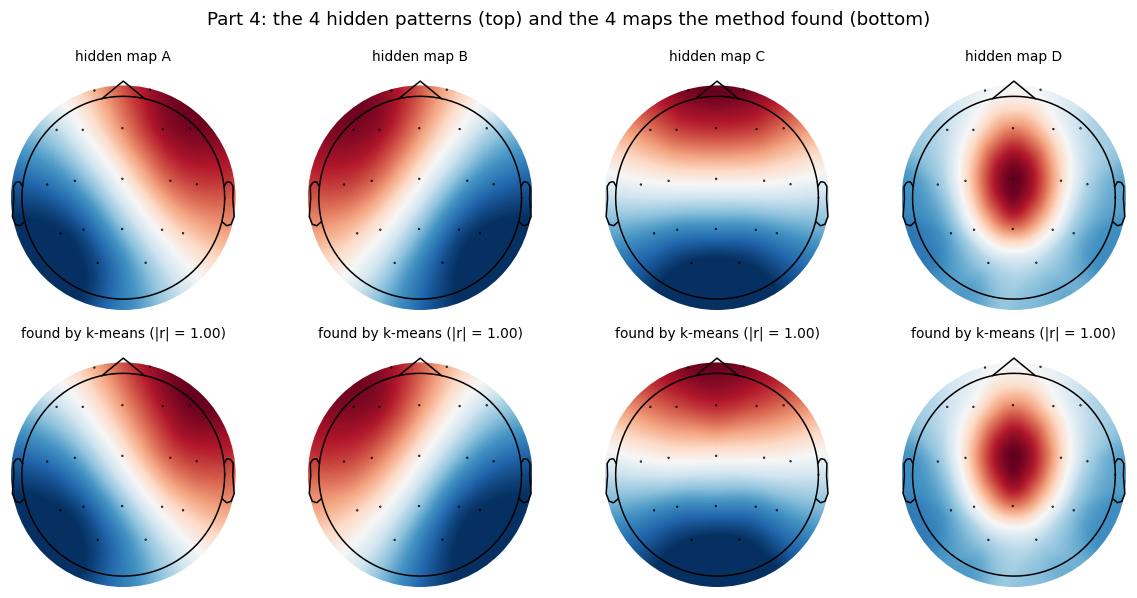

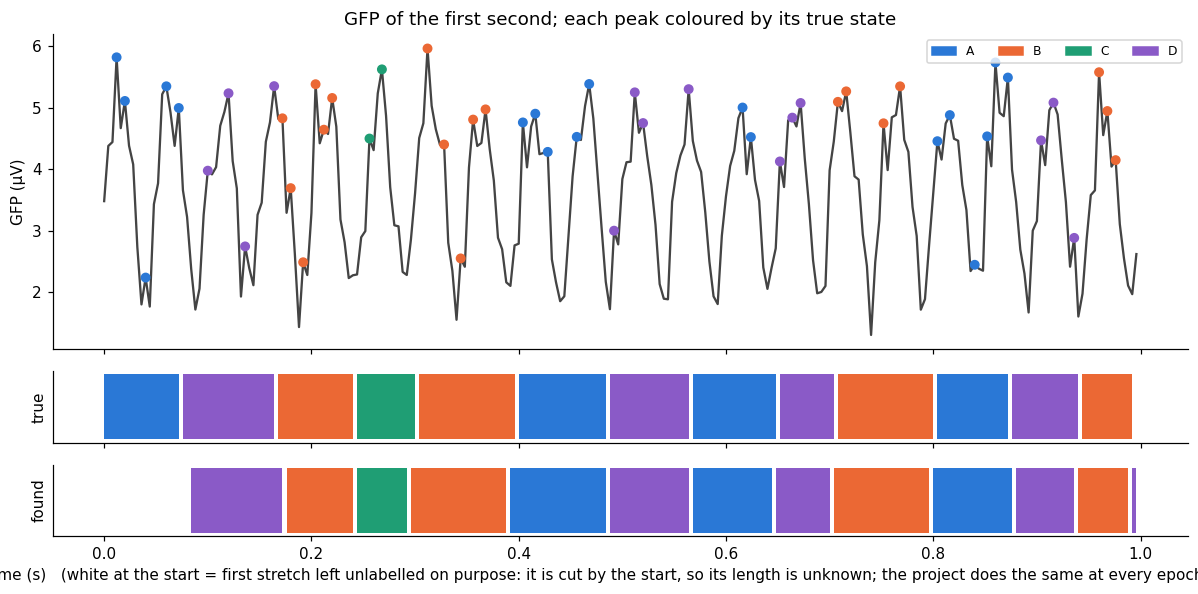

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for j, L in enumerate(letters):
    k = [kk for kk, jj in found_to_true.items() if jj == j][0]
    m = found[k] if np.corrcoef(found[k], true_maps[j])[0, 1] >= 0 else -found[k]
    topo(axes[0, j], true_maps[j], raw4.info, f"hidden map {L}")
    topo(axes[1, j], m, raw4.info, f"found by k-means (|r| = {sim[k, j]:.2f})")
plt.suptitle("Part 4: the 4 hidden patterns (top) and the 4 maps the method found (bottom)")
plt.tight_layout(); plt.show()

colours = ["#2a78d6", "#eb6834", "#1f9e74", "#8a5ac7"]
show = slice(0, fs4)                                   # first second
fig, axes = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 0.5, 0.5]})
g4 = gfp(data4)
pk, _ = find_peaks(g4, distance=2)
pk = pk[pk < fs4]
axes[0].plot(t4[show], g4[show] * 1e6, color="#444444")
axes[0].scatter(t4[pk], g4[pk] * 1e6, c=[colours[s] for s in true_seq[pk]], s=30, zorder=3)
axes[0].set(ylabel="GFP (µV)", title="GFP of the first second; each peak coloured by its true state")
for ax, seq, name in [(axes[1], true_seq, "true"), (axes[2], lab_true_order, "found")]:
    for s in range(4):
        ax.fill_between(t4[show], 0, 1, where=seq[show] == s, color=colours[s], step="mid", lw=0)
    ax.set(yticks=[], ylabel=name)
axes[2].set_xlabel("time (s)   (white at the start = first stretch left unlabelled on purpose: it is cut by the start, so its length is unknown; the project does the same at every epoch edge)")
handles = [plt.Rectangle((0, 0), 1, 1, color=colours[s]) for s in range(4)]
axes[0].legend(handles, letters, ncol=4, loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**What Part 4 tells:** from nothing but the 19-channel signal, the method finds the 4 hidden
patterns again and labels almost every sample with the right one (the errors are near the switches
and the zero-crossings, where GFP is low). From the label sequence we then count our features:
how long each state lasts (**duration**), how often it starts per second (**occurrence**), the share
of time (**coverage**) and which state follows which (**transition probabilities**).

In [8]:
def durations_ms(seq, fs):
    # mean length of the stretches of each state, in ms (stretches cut by the start/end are kept here)
    out = {s: [] for s in range(4)}
    start = 0
    for i in range(1, len(seq) + 1):
        if i == len(seq) or seq[i] != seq[start]:
            if seq[start] >= 0:
                out[seq[start]].append((i - start) / fs * 1000)
            start = i
    return {letters[s]: round(float(np.mean(v)), 1) for s, v in out.items()}
print("mean duration (ms), true :", durations_ms(true_seq, fs4))
print("mean duration (ms), found:", durations_ms(lab_true_order, fs4))

mean duration (ms), true : {'A': 79.5, 'B': 79.1, 'C': 71.7, 'D': 78.3}
mean duration (ms), found: {'A': 80.0, 'B': 79.5, 'C': 70.2, 'D': 78.8}


## Part 5 - the same picture on 2 seconds of real EEG (subject h01)

Cleaned exactly as in the project (bad channels rebuilt, 2–20 Hz, average reference). Each peak is
coloured by the project's shared map it is closest to. Real EEG is less tidy than Part 4, but the
idea is the same: GFP rises and falls, and around each peak one map holds for a while.

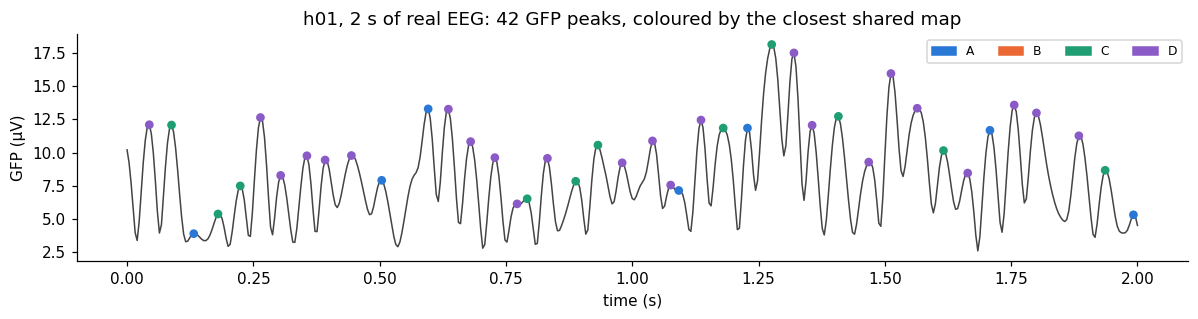

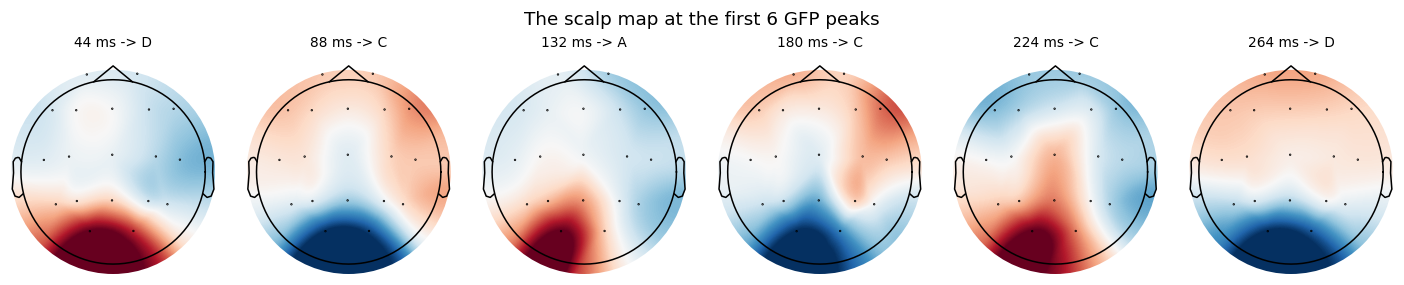

In [9]:
real = pre.load_clean("h01.edf")
shared = mm.load_model()
seg_real = real.copy().crop(60, 62)                        # 2 seconds, from minute 1
d = seg_real.get_data()
g5 = gfp(d)
p5, _ = find_peaks(g5, distance=2)
maps = np.asarray(shared.cluster_centers_)
dz = (d - d.mean(0)) / d.std(0)
mz = ((maps.T - maps.mean(1)) / maps.std(1)).T
state_at_peak = np.argmax(np.abs(mz @ dz[:, p5]) / 19, axis=0)     # closest shared map, sign ignored
order = {"A": 0, "B": 1, "C": 2, "D": 3}
t5 = np.arange(d.shape[1]) / real.info["sfreq"]

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t5, g5 * 1e6, color="#444444", lw=1)
ax.scatter(t5[p5], g5[p5] * 1e6, s=22, zorder=3,
           c=[colours[order[mm.STATE_NAMES[int(s)]]] for s in state_at_peak])
ax.legend(handles, letters, ncol=4, loc="upper right", fontsize=8)
ax.set(xlabel="time (s)", ylabel="GFP (µV)",
       title=f"h01, 2 s of real EEG: {len(p5)} GFP peaks, coloured by the closest shared map")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, i in zip(axes, p5[:6]):
    s = mm.STATE_NAMES[int(state_at_peak[list(p5).index(i)])]
    topo(ax, d[:, i], real.info, f"{t5[i]*1000:.0f} ms -> {s}")
plt.suptitle("The scalp map at the first 6 GFP peaks")
plt.tight_layout(); plt.show()

## Summary - answers to the questions

| Question | Answer |
|---|---|
| What is GFP? | At each sample, the standard deviation of the 19 electrode voltages (after average reference). One number per sample: how strong the scalp field is at that moment. |
| x-axis and y-axis of a GFP plot? | x = **time** (s or ms), y = **GFP in µV**. Not frequency. |
| How are the peaks found? | A peak is a sample with a higher GFP than both neighbours (local maximum). `extract_gfp_peaks(raw, min_peak_distance=2)` = `np.std(data, axis=0)` then `scipy.signal.find_peaks(gfp, distance=2)`. |
| Why use the peaks? | At a peak the map is strongest and cleanest (Part 2: \|corr\| ≈ 1); near GFP minima the map is mostly noise. The map stays about the same around a peak, so the peaks are good snapshots. It also reduces the data (about 1,500 maps per subject instead of 225,000 samples). |
| Why 2 peaks per cycle? | The field is strong at the top and at the bottom of the wave (same map, opposite sign). That is also why polarity is ignored. |
| Fourier vs GFP? | Fourier transform: which **frequencies** are there (x = Hz). GFP: **when** the field is strong (x = time). |
| What does k-means do with the peaks? | Groups the peak maps into 4 groups of similar shape (sign ignored) and gives one average map per group = the 4 microstates (Part 4 shows it finds hidden maps again). |
| How do we get the sequence? | Every sample (not only peaks) gets the most similar of the 4 maps, then light smoothing removes one-sample flickers. From that sequence we count duration, occurrence, coverage and transitions. |
| What do the red and blue regions mean? | Opposite voltage at one moment. Only the **pattern** matters, not the colour (flipped colours = same state), and a red region does not mean "more brain activity there". |